# Clase 20 · De una grabación al texto

**Recorrido:** primero se prueba un WAV público guardado como `data/example_es.wav`; después se transcriben, por separado, las grabaciones propias `data/A1_clara.wav` y `data/A1_ruido.wav`.
El ejemplo público nunca se guarda con el nombre de una grabación propia.

Selecciona **UNIE_VozClon**, reinicia el kernel y avanza por las celdas. La sección de micrófono es una demostración opcional e independiente; la comparación final carga los dos archivos propios existentes en `data/`.

Las descargas del WAV de ejemplo y de los pesos están señaladas y usan `data/`.


In [21]:
import os
os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import wave
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import matplotlib.pyplot as plt
import sounddevice as sd
from scipy.signal import spectrogram
from IPython.display import Audio, display

%matplotlib inline
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}


## 1. Caso de ejemplo público

### 1.1. Cargar, reproducir y ver la señal

**Descarga del ejemplo.** WAV de habla en español, PCM de 16 bits y un canal,
distribuido como [ejemplo por SpeechBrain](https://huggingface.co/speechbrain/asr-wav2vec2-commonvoice-14-es/blob/main/example_es.wav).
Se conserva exclusivamente en `data/example_es.wav`; nunca sobrescribe
`data/A1_clara.wav` ni `data/A1_ruido.wav`.
La división entre 32768 expresa las muestras enteras en la escala de amplitud de −1 a 1.


In [50]:
ruta = Path("data/example_es.wav")
url = ("https://huggingface.co/speechbrain/asr-wav2vec2-commonvoice-14-es/"
       "resolve/main/example_es.wav")
if not ruta.exists():
    ruta.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(url, ruta)
with wave.open(str(ruta), "rb") as wav:
    if wav.getnchannels() != 1 or wav.getsampwidth() != 2:
        raise ValueError("El ejemplo debe ser un WAV mono PCM de 16 bits.")
    fs = wav.getframerate()
    audio = np.frombuffer(wav.readframes(wav.getnframes()), dtype="<i2")
audio = audio.astype(np.float32) / 32768
origen = "WAV público de SpeechBrain: data/example_es.wav"


WAV público de SpeechBrain: data/example_es.wav
shape: (133103,) | fs: 48000 Hz | audio: 2.773 s


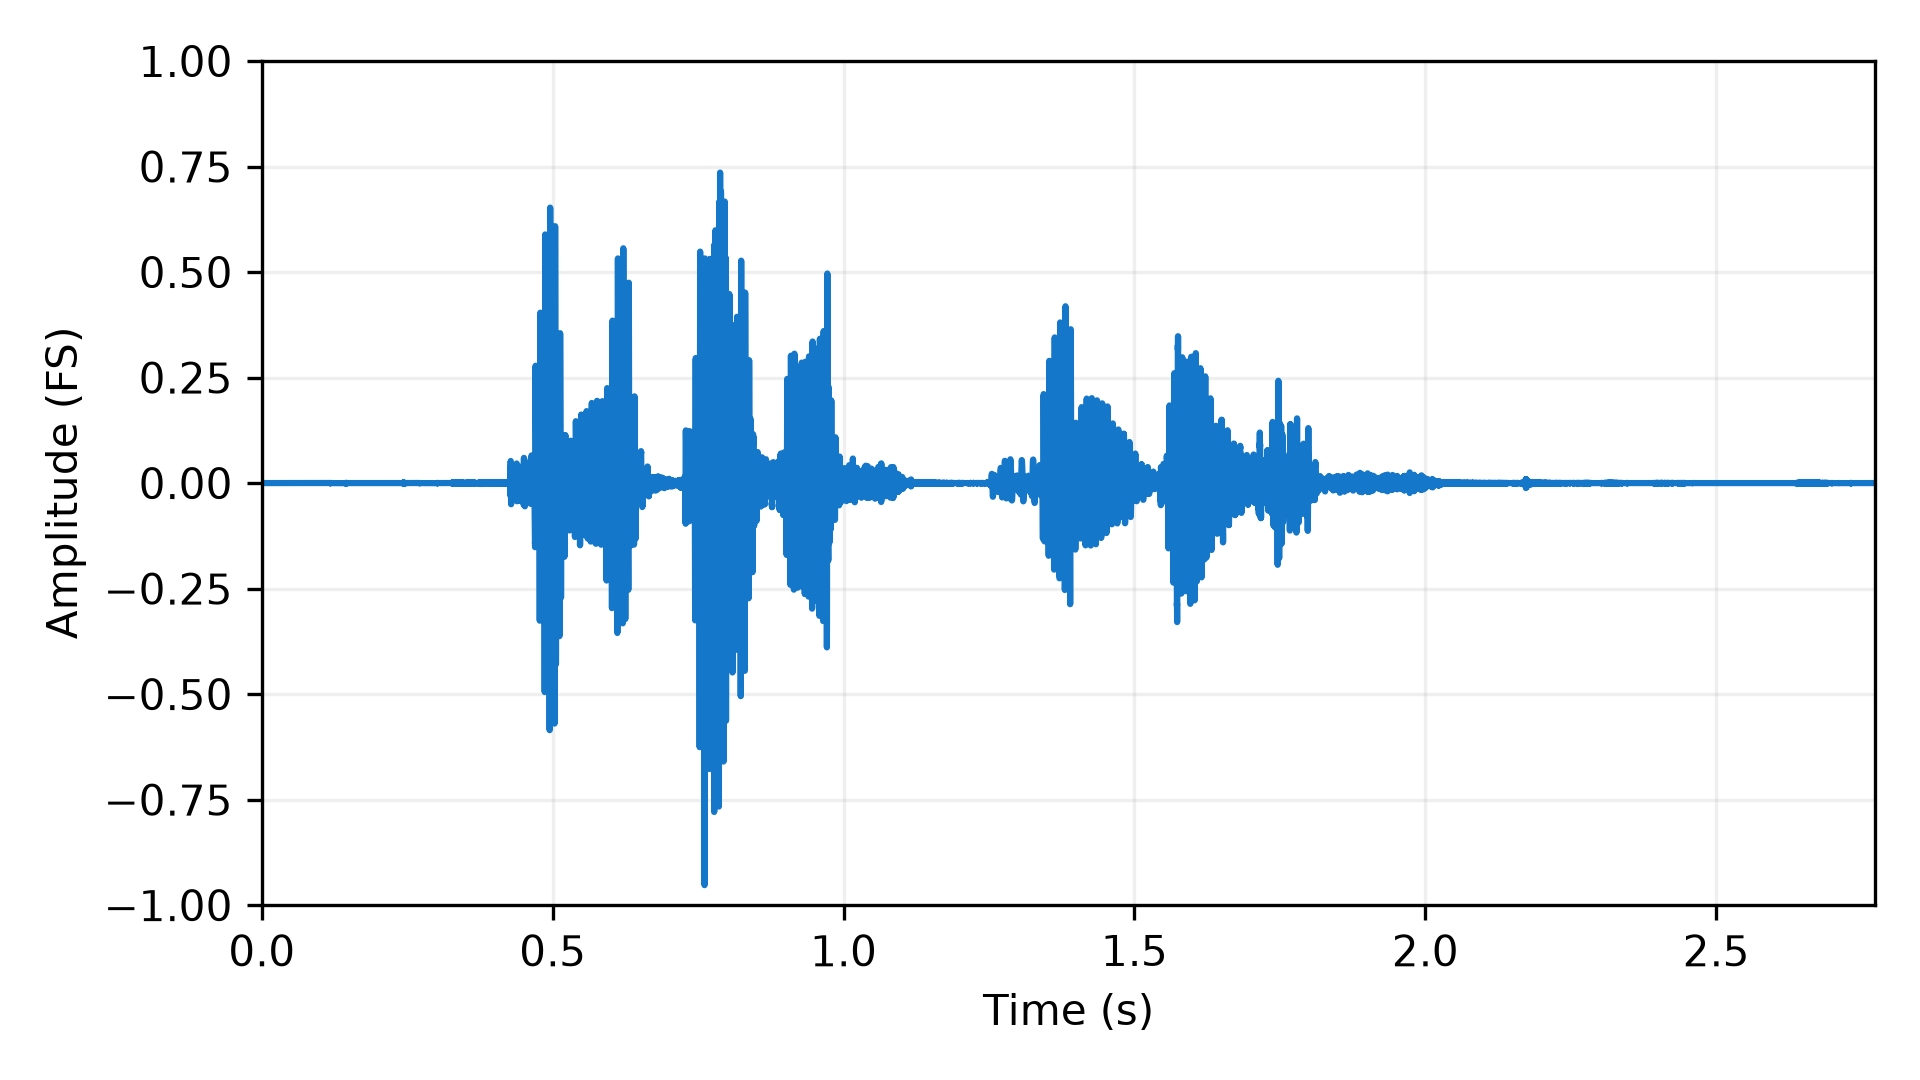

In [51]:
if audio is None or len(audio) == 0 or not np.isfinite(audio).all():
    raise ValueError("Primero completa una grabación o carga el ejemplo.")
if np.max(np.abs(audio)) == 0:
    raise ValueError("La señal contiene solo ceros. Revisa la entrada y vuelve a grabar.")

print(origen)
print(f"shape: {audio.shape} | fs: {fs} Hz | audio: {len(audio) / fs:.3f} s")
display(Audio(audio, rate=fs, normalize=False))

tiempo = np.arange(len(audio)) / fs
fig, ax = plt.subplots(figsize=(6.4, 3.6), dpi=300)
ax.plot(tiempo, audio, color="#1477C9")
ax.set(xlabel="Time (s)", ylabel="Amplitude (FS)",
       xlim=(0, len(audio) / fs), ylim=(-1, 1))
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


### 1.2. Inspeccionar las muestras

`audio[n]` es la amplitud de una muestra; su instante es `n / fs`.
Ampliamos un fragmento alrededor del máximo absoluto de esta misma grabación.
Los puntos son las muestras; las líneas solo las unen para facilitar la lectura.

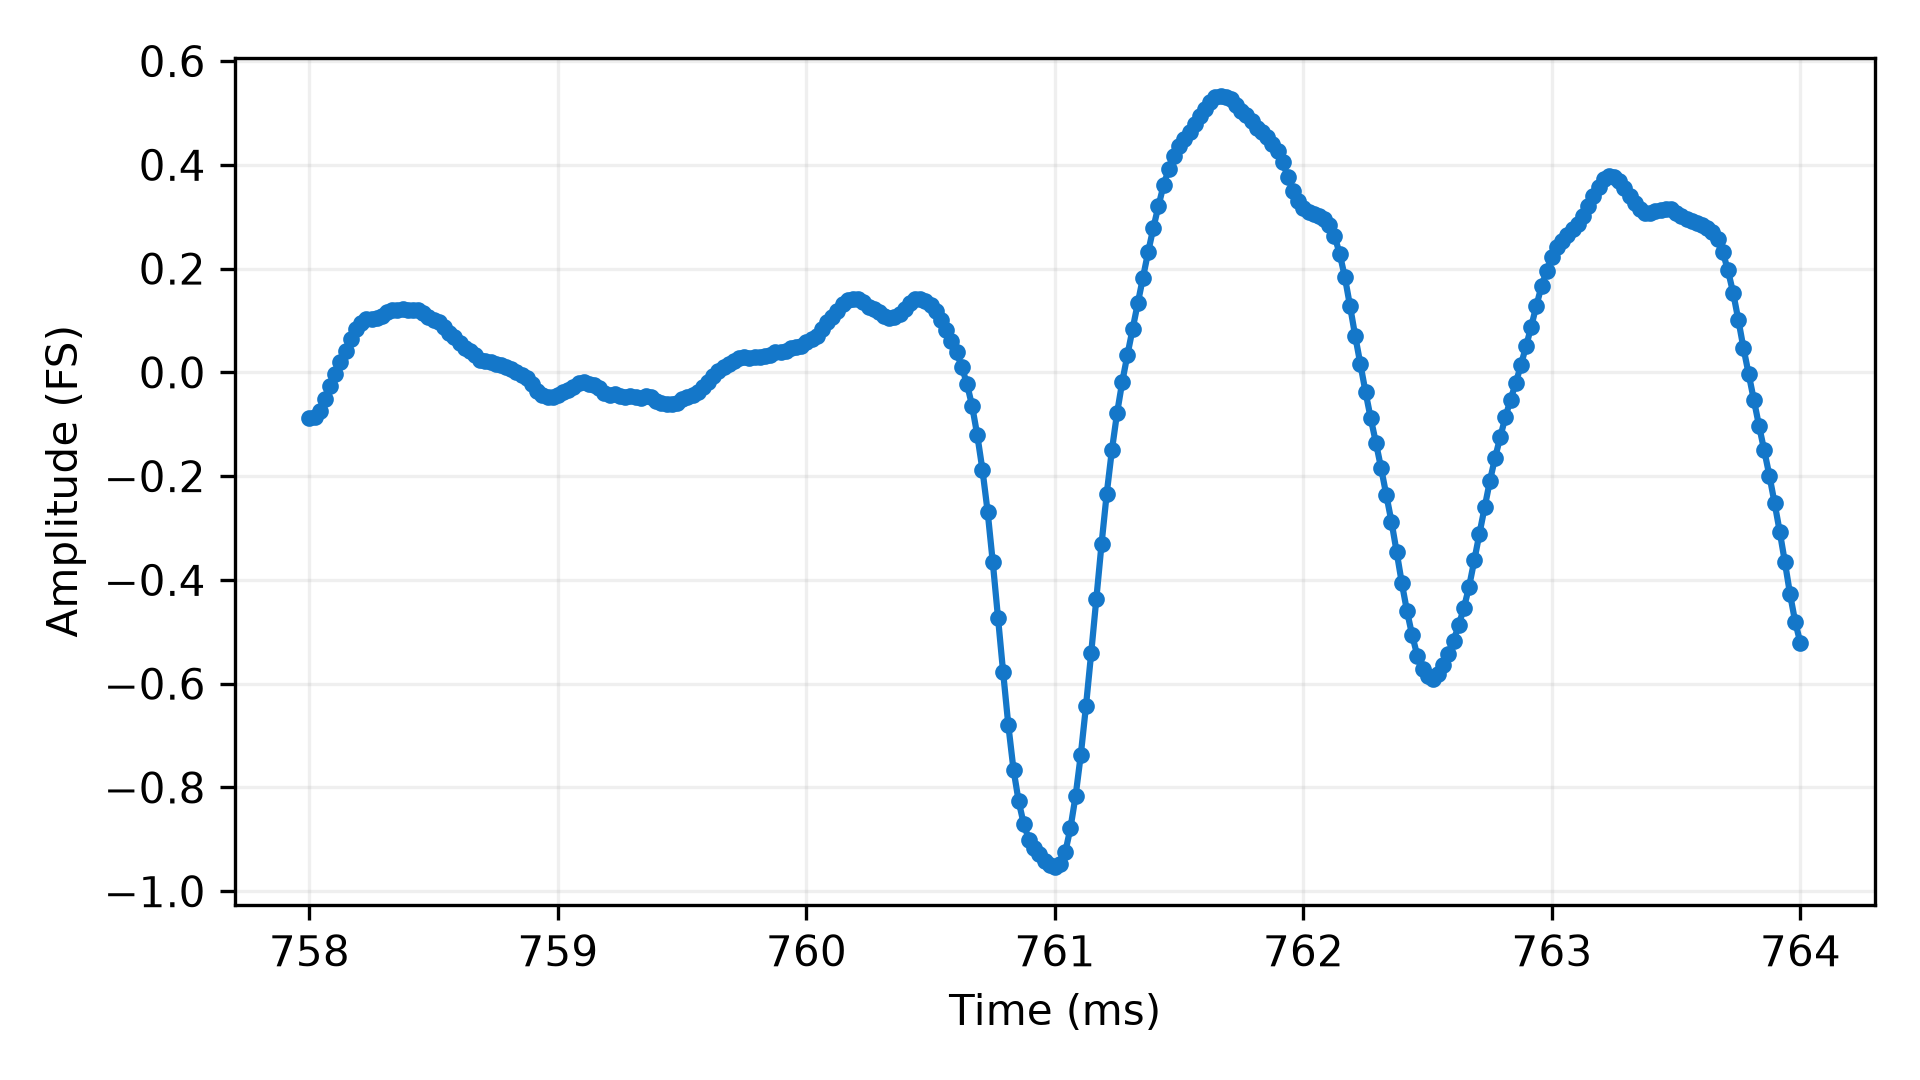

Separación entre muestras: 0.0208 ms


In [52]:
centro = int(np.argmax(np.abs(audio)))
margen = round(0.003 * fs)
inicio = max(0, centro - margen)
fin = min(len(audio), centro + margen + 1)
indices = np.arange(inicio, fin)

fig, ax = plt.subplots(figsize=(6.4, 3.6), dpi=300)
ax.plot(1000 * indices / fs, audio[indices], ".-", color="#1477C9")
ax.set(xlabel="Time (ms)", ylabel="Amplitude (FS)")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
print(f"Separación entre muestras: {1000 / fs:.4f} ms")


### 1.3. Calcular el espectrograma

Cada ventana Hann selecciona un fragmento. La FFT permite calcular su potencia
por frecuencia; al desplazar la ventana obtenemos las columnas del espectrograma.
`hop` es el avance entre ventanas. Usamos 32 ms y un solapamiento del 75 %.

El color representa **PSD en dB re 1 FS²/Hz**: `10·log10(PSD / 1 FS²/Hz)`.
La escala es fija para comparar grabaciones; no mide presión sonora en dB SPL.

In [53]:
VENTANA_MS = 32
SOLAPAMIENTO = 0.75
FRECUENCIA_MAX = 8000

n_fft = round(fs * VENTANA_MS / 1000)
hop = max(1, round(n_fft * (1 - SOLAPAMIENTO)))
if n_fft < 2 or n_fft > len(audio) or not 0 <= SOLAPAMIENTO < 1:
    raise ValueError("Revisa la ventana, el solapamiento y la longitud del audio.")

frecuencias, instantes, psd = spectrogram(
    audio, fs=fs, window="hann", nperseg=n_fft, noverlap=n_fft - hop,
    detrend=False, scaling="density", mode="psd"
)
db = 10 * np.log10(np.maximum(psd, 1e-20))
visibles = frecuencias <= min(FRECUENCIA_MAX, fs / 2)
print(f"Ventana: {n_fft} muestras | hop: {hop} muestras")
print(f"shape (frequency, time): {psd.shape}")
print(f"Separación de bins: {fs / n_fft:.2f} Hz | avance: {1000 * hop / fs:.2f} ms")


Ventana: 1536 muestras | hop: 384 muestras
shape (frequency, time): (769, 343)
Separación de bins: 31.25 Hz | avance: 8.00 ms


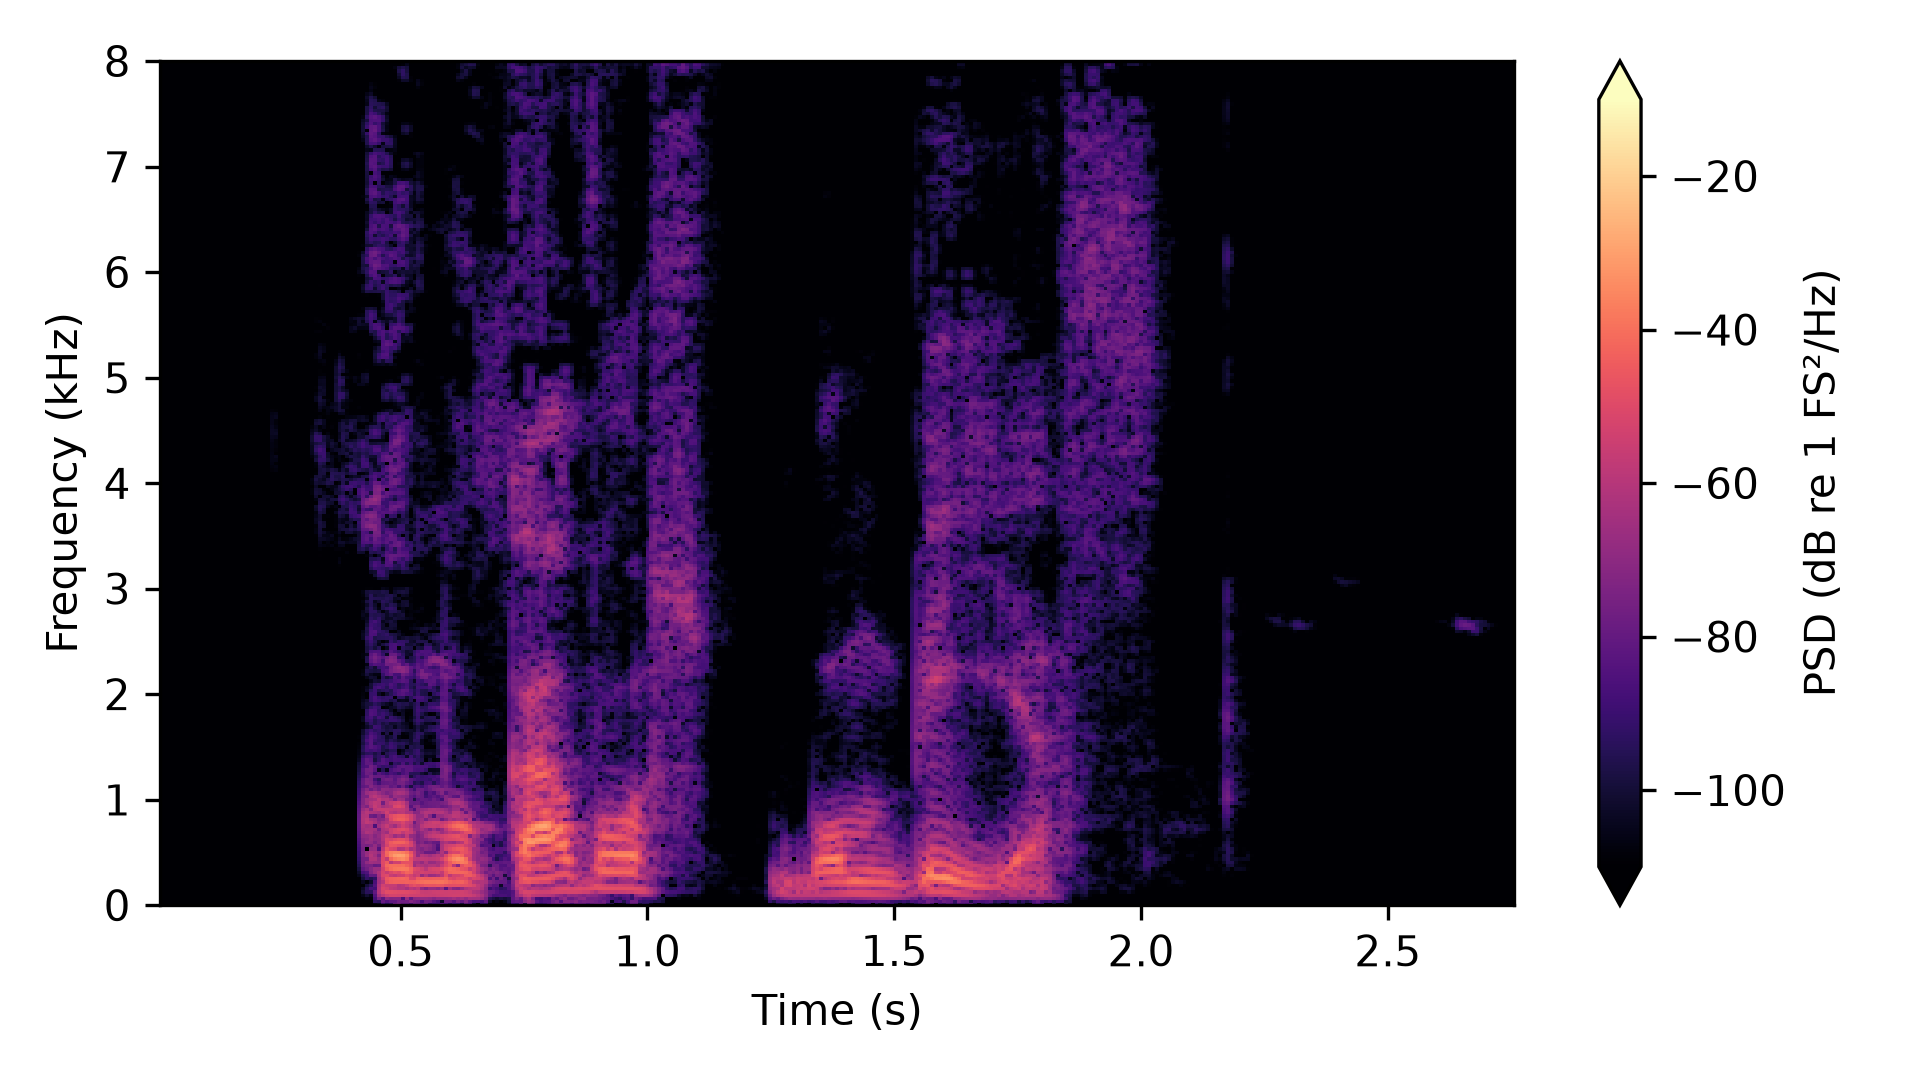

In [54]:
fig, ax = plt.subplots(figsize=(6.4, 3.6), dpi=300)
imagen = ax.pcolormesh(instantes, frecuencias[visibles] / 1000, db[visibles],
                       shading="nearest", cmap="magma", vmin=-110, vmax=-10)
ax.set(xlabel="Time (s)", ylabel="Frequency (kHz)",
       ylim=(0, min(FRECUENCIA_MAX, fs / 2) / 1000))
fig.colorbar(imagen, ax=ax, label="PSD (dB re 1 FS²/Hz)", extend="both")
fig.tight_layout()
plt.show()


Cambia `VENTANA_MS` a 16 y después a 64, recalculando las dos celdas anteriores
sobre el mismo audio. Observa la separación de frecuencias y cómo se extienden
los cambios breves en el tiempo.

### 1.4. Transcribir español con Wav2Vec2

La aplicación final es un **dictado**: obtener el texto pronunciado.
En reconocimiento de hablante se comparan características de la voz para
buscar o verificar una identidad; esta salida de caracteres resuelve otra tarea.

Usamos **Wav2Vec2 / VoxPopuli en español**, ya adaptado a transcripción por sus
autores. Mantendremos sus pesos fijos. Recibe la **forma de onda mono a 16 kHz**;
sus filtros aprendidos extraen las características. El espectrograma anterior
sirve para analizar el audio, pero no se introduce como entrada en este modelo.

**Descarga de pesos.** La primera ejecución obtiene aproximadamente **378 MB**
desde `download.pytorch.org` y los conserva en `data/`. Después reutiliza el archivo.
La inferencia se realiza localmente en CPU.

[Modelo y licencia CC BY-NC 4.0](https://docs.pytorch.org/audio/2.2.0/generated/torchaudio.pipelines.VOXPOPULI_ASR_BASE_10K_ES.html).

In [35]:
import torch
import torchaudio

bundle = torchaudio.pipelines.VOXPOPULI_ASR_BASE_10K_ES
modelo = bundle.get_model(dl_kwargs={"model_dir": "data", "weights_only": True})
modelo.eval()
modelo.requires_grad_(False)
etiquetas = bundle.get_labels()
print(f"Wav2Vec2 · español · entrada a {bundle.sample_rate} Hz")
print(f"Torch {torch.__version__} | TorchAudio {torchaudio.__version__}")


Wav2Vec2 · español · entrada a 16000 Hz
Torch 2.8.0+cu128 | TorchAudio 2.8.0+cu128


El resampling cambia el número de muestras manteniendo la duración de la frase.
Añadimos el eje de batch: la entrada tiene shape `(1, samples)`.

In [36]:
entrada = torch.from_numpy(audio).unsqueeze(0)
if fs != bundle.sample_rate:
    entrada = torchaudio.functional.resample(entrada, fs, bundle.sample_rate)

print(f"Entrada: {tuple(entrada.shape)}")
print(f"Audio original: {len(audio) / fs:.4f} s")
print(f"Audio del modelo: {entrada.shape[1] / bundle.sample_rate:.4f} s")


Entrada: (1, 96000)
Audio original: 6.0000 s
Audio del modelo: 6.0000 s


La red produce **logits** por frame y carácter. La decodificación CTC greedy
elige el mayor valor de cada frame, colapsa repeticiones consecutivas y después
elimina el símbolo blank (`-`). `|` representa una separación entre palabras.
Un blank entre dos letras iguales permite conservar ambas: el orden de esas
operaciones importa.

In [37]:
with torch.inference_mode():
    logits, _ = modelo(entrada)

camino = logits[0].argmax(dim=-1)
sin_repeticiones = torch.unique_consecutive(camino)
texto = "".join(etiquetas[i] for i in sin_repeticiones.tolist() if i != 0)
texto = " ".join(texto.replace("|", " ").split())

print(f"Logits (batch, frames, tokens): {tuple(logits.shape)}")
print("Camino CTC:", "".join(etiquetas[i] for i in camino.tolist()))
print()
print("Transcripción:", texto if texto else "[Sin texto reconocido]")


Logits (batch, frames, tokens): (1, 299, 35)
Camino CTC: ------------------------------p--o-----l--a---|--------------s---o---i----s-----a--n-----t-i-----||------------------------------------------------------y--||--mme-||---g-uu--s--t--a||||||---m-u----chhoo-||||---j-u----g--a-r|||-a-l-|-----g--------t-e---|--a---|--s--e----i----s--------a-------------

Transcripción: pola soisanti y me gusta mucho jugar al gte a seisa


Reproduce el ejemplo público y contrasta lo que escuchas con la transcripción obtenida.
La sección siguiente de micrófono es opcional; al final se cargan explícitamente
`data/A1_clara.wav` y `data/A1_ruido.wav` para compararlos con el mismo modelo.

## 2. Captura opcional con micrófono


In [38]:
api = next((a for a in sd.query_hostapis()
            if a["name"] == "Windows WASAPI"), None)
entradas = api["devices"] if api else range(len(sd.query_devices()))
for numero in entradas:
    entrada_dispositivo = sd.query_devices(numero)
    if entrada_dispositivo["max_input_channels"] > 0:
        print(numero, entrada_dispositivo["name"])

9 Varios micrófonos (Realtek(R) Audio)


In [39]:
DISPOSITIVO = None     # O el número de una entrada de la lista.
SEGUNDOS = 6           # Longitud de la grabación.

if DISPOSITIVO is None:
    DISPOSITIVO = api["default_input_device"] if api else sd.default.device[0]
if DISPOSITIVO < 0:
    raise RuntimeError("No hay micrófono disponible. Selecciona una entrada.")

**Esta celda inicia la captura.** Pronuncia una frase breve en español, por ejemplo:
«Hoy vamos a representar una señal de audio». `sd.wait` espera al final;
`finally` libera el micrófono también si interrumpes la celda.

Al terminar, se guarda la grabación completa en un WAV dentro de `data/`.
El nombre incluye fecha, hora y microsegundos; si ya existe, no se sobrescribe.


In [42]:
from datetime import datetime
from scipy.io import wavfile

audio_micro = None
fs_micro = int(sd.query_devices(DISPOSITIVO, "input")["default_samplerate"])
sd.check_input_settings(device=DISPOSITIVO, channels=1,
                        dtype="float32", samplerate=fs_micro)
print("Grabando…", flush=True)
try:
    grabacion = sd.rec(round(SEGUNDOS * fs_micro), samplerate=fs_micro,
                       channels=1, dtype="float32", device=DISPOSITIVO)
    estado = sd.wait()
finally:
    sd.stop()
if estado:
    raise RuntimeError(f"Captura incompleta: {estado}. Vuelve a grabar.")
audio_micro = grabacion[:, 0].copy()
origen_micro = "Micrófono"
Path("data").mkdir(exist_ok=True)
ruta_micro = Path("data") / f"microfono_{datetime.now():%Y-%m-%d_%H-%M-%S_%f}.wav"
with ruta_micro.open("xb") as archivo:
    wavfile.write(archivo, fs_micro, audio_micro)
print(f"Grabación guardada en: {ruta_micro}")

Grabando…
Grabación guardada en: data\microfono_2026-11-23_19-53-08_574333.wav


### 2.2. Escuchar y ver la grabación completa

Usa el eje de tiempo de esta gráfica para elegir después el intervalo que quieres ampliar.

Micrófono
shape: (288000,) | fs: 48000 Hz | audio: 6.000 s


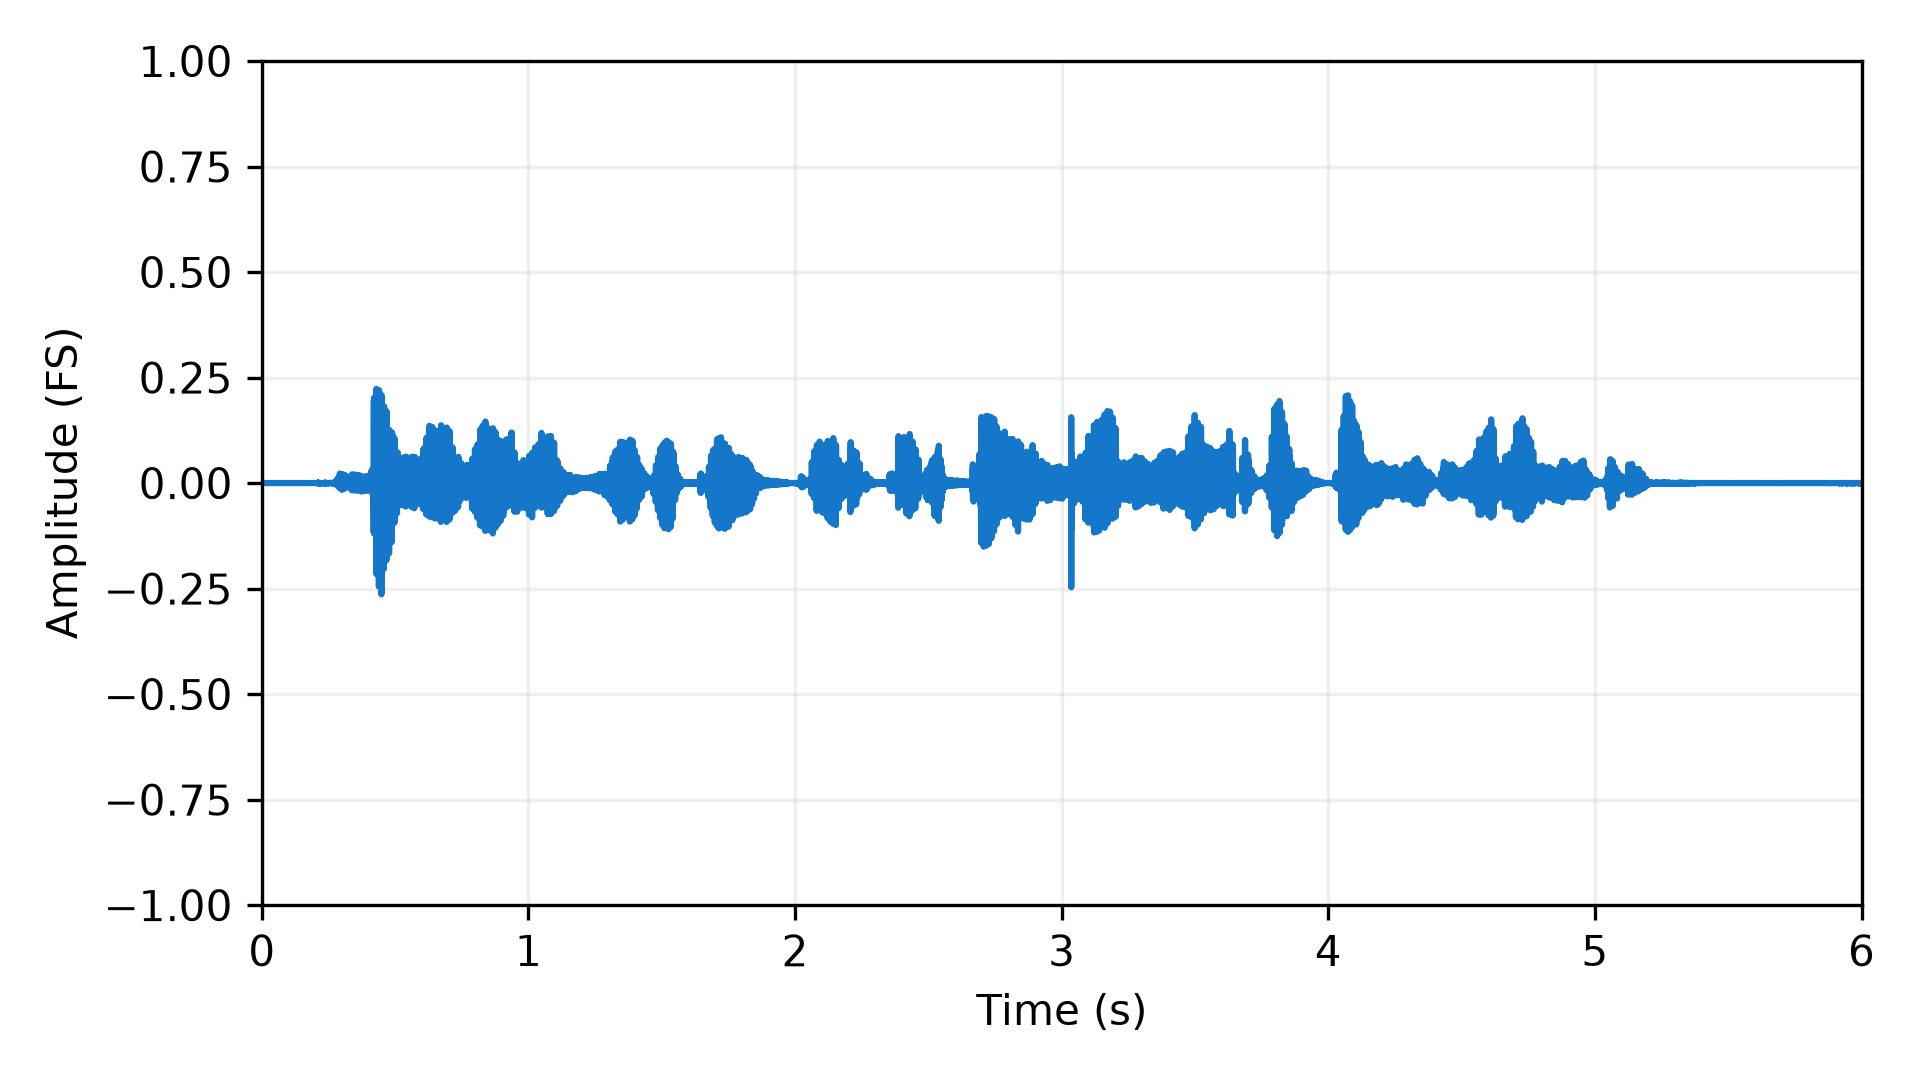

In [43]:
if audio_micro is None or len(audio_micro) == 0 or not np.isfinite(audio_micro).all():
    raise ValueError("Primero completa una grabación o carga el ejemplo.")
if np.max(np.abs(audio_micro)) == 0:
    raise ValueError("La señal contiene solo ceros. Revisa la entrada y vuelve a grabar.")

print(origen_micro)
print(f"shape: {audio_micro.shape} | fs: {fs_micro} Hz | audio: {len(audio_micro) / fs_micro:.3f} s")
display(Audio(audio_micro, rate=fs_micro, normalize=False))

tiempo_micro = np.arange(len(audio_micro)) / fs_micro
fig_micro, ax_micro = plt.subplots(figsize=(6.4, 3.6), dpi=300)
ax_micro.plot(tiempo_micro, audio_micro, color="#1477C9")
ax_micro.set(xlabel="Time (s)", ylabel="Amplitude (FS)",
       xlim=(0, len(audio_micro) / fs_micro), ylim=(-1, 1))
ax_micro.grid(alpha=0.2)
fig_micro.tight_layout()
plt.show()

### 2.3. Elegir dónde ampliar las muestras

Escribe **`INICIO_S` y `FIN_S`** en segundos de la grabación completa.
Por ejemplo, `1.000` y `1.006` muestran las muestras entre esos dos instantes.
Cambia los límites y vuelve a ejecutar esta celda para ver otro fragmento.
Esta ampliación conserva la grabación completa para el espectrograma y la transcripción.

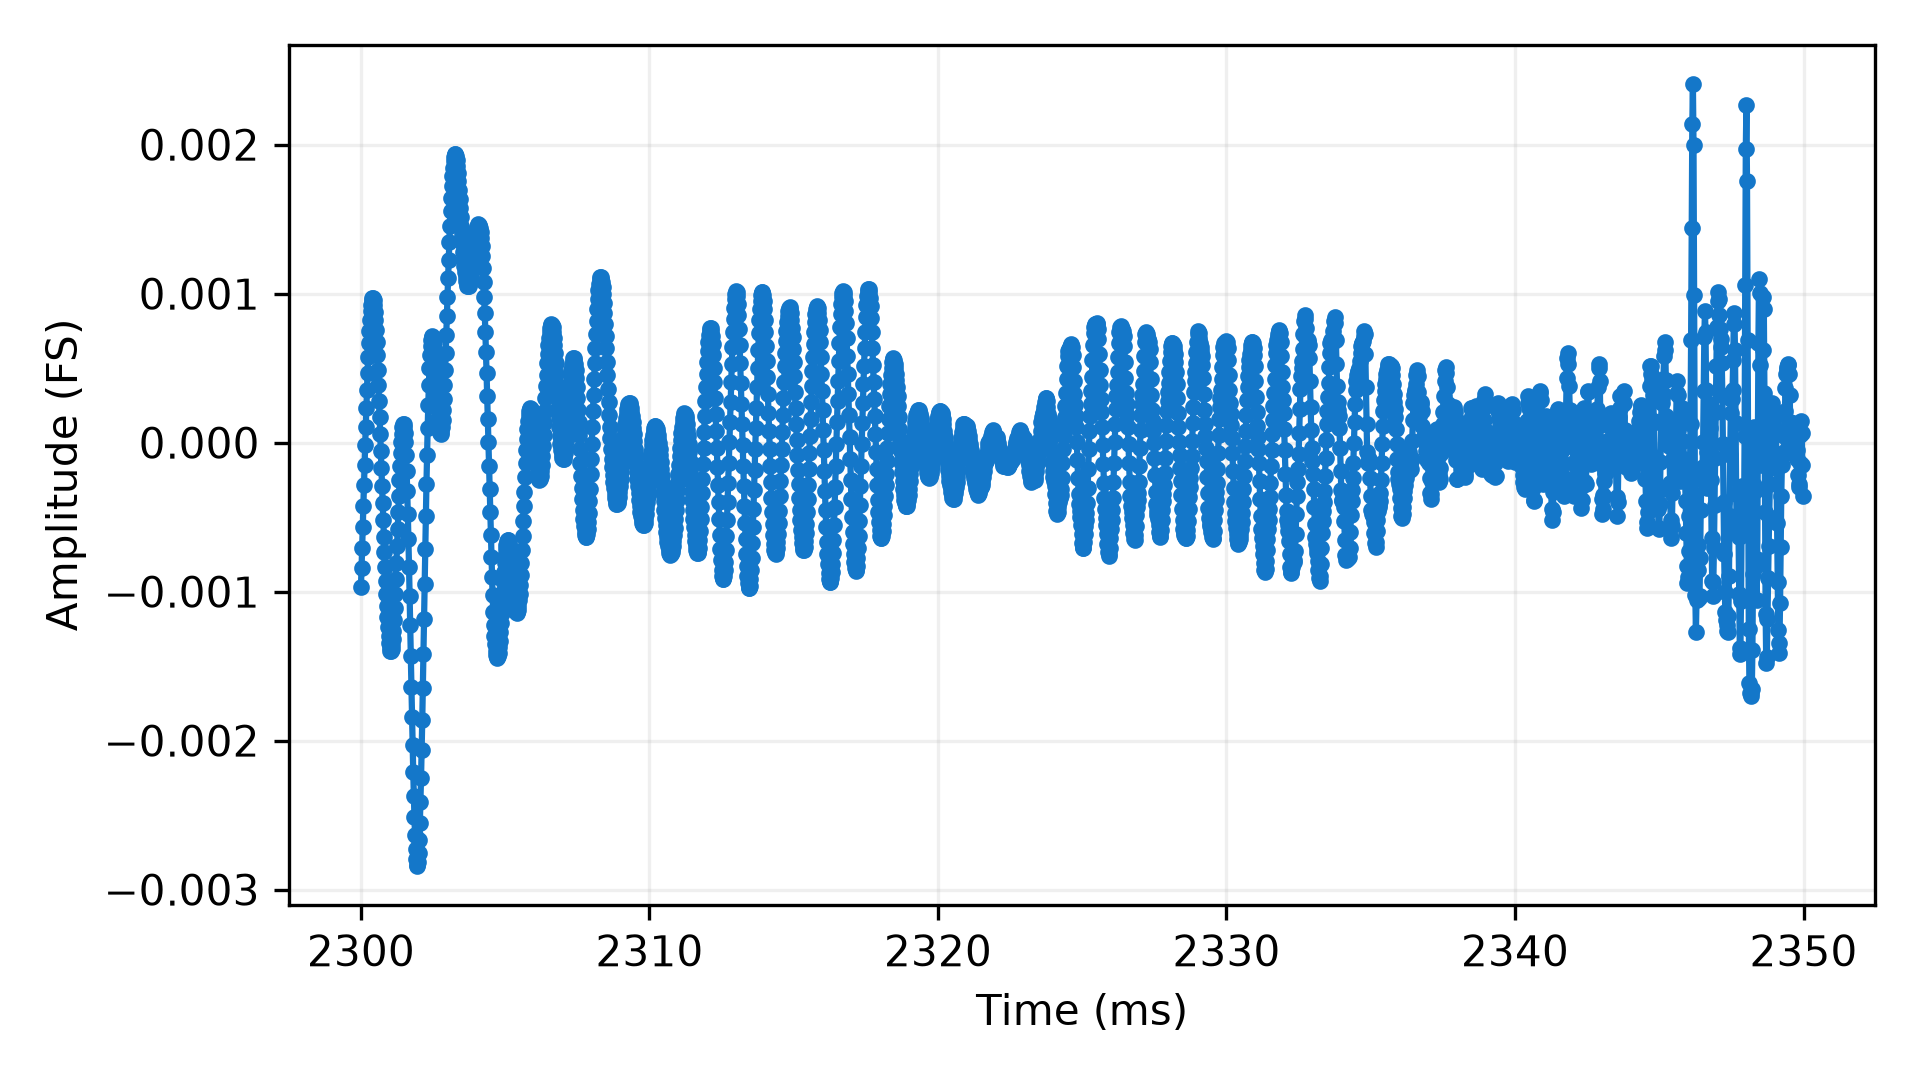

Intervalo elegido: 2.300000–2.350000 s | muestras: 2400


In [44]:
INICIO_S = 2.300
FIN_S = 2.350

duracion_micro = len(audio_micro) / fs_micro
if not np.isfinite([INICIO_S, FIN_S]).all() or not 0 <= INICIO_S < FIN_S <= duracion_micro:
    raise ValueError(f"Elige 0 <= INICIO_S < FIN_S <= {duracion_micro:.6f} s.")
inicio_muestra = int(np.ceil(INICIO_S * fs_micro))
fin_muestra = int(np.ceil(FIN_S * fs_micro))
indices_micro = np.arange(inicio_muestra, fin_muestra)
if len(indices_micro) < 2:
    raise ValueError("Amplía el intervalo para incluir al menos dos muestras.")

fig, ax = plt.subplots(figsize=(6.4, 3.6), dpi=300)
ax.plot(1000 * indices_micro / fs_micro, audio_micro[indices_micro], ".-", color="#1477C9")
ax.set(xlabel="Time (ms)", ylabel="Amplitude (FS)")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
print(f"Intervalo elegido: {INICIO_S:.6f}–{FIN_S:.6f} s | muestras: {len(indices_micro)}")

### 2.4. Espectrograma de tu grabación

Aplicamos el mismo cálculo y la misma escala de color del ejemplo.

In [45]:
VENTANA_MS_MICRO = 32
SOLAPAMIENTO_MICRO = 0.75
FRECUENCIA_MAX_MICRO = 8000

n_fft_micro = round(fs_micro * VENTANA_MS_MICRO / 1000)
hop_micro = max(1, round(n_fft_micro * (1 - SOLAPAMIENTO_MICRO)))
if n_fft_micro < 2 or n_fft_micro > len(audio_micro) or not 0 <= SOLAPAMIENTO_MICRO < 1:
    raise ValueError("Revisa la ventana, el solapamiento y la longitud del audio.")

frecuencias_micro, instantes_micro, psd_micro = spectrogram(
    audio_micro, fs=fs_micro, window="hann", nperseg=n_fft_micro, noverlap=n_fft_micro - hop_micro,
    detrend=False, scaling="density", mode="psd"
)
db_micro = 10 * np.log10(np.maximum(psd_micro, 1e-20))
visibles_micro = frecuencias_micro <= min(FRECUENCIA_MAX_MICRO, fs_micro / 2)
print(f"Ventana: {n_fft_micro} muestras | hop: {hop_micro} muestras")
print(f"shape (frequency, time): {psd_micro.shape}")
print(f"Separación de bins: {fs_micro / n_fft_micro:.2f} Hz | avance: {1000 * hop_micro / fs_micro:.2f} ms")

Ventana: 1536 muestras | hop: 384 muestras
shape (frequency, time): (769, 747)
Separación de bins: 31.25 Hz | avance: 8.00 ms


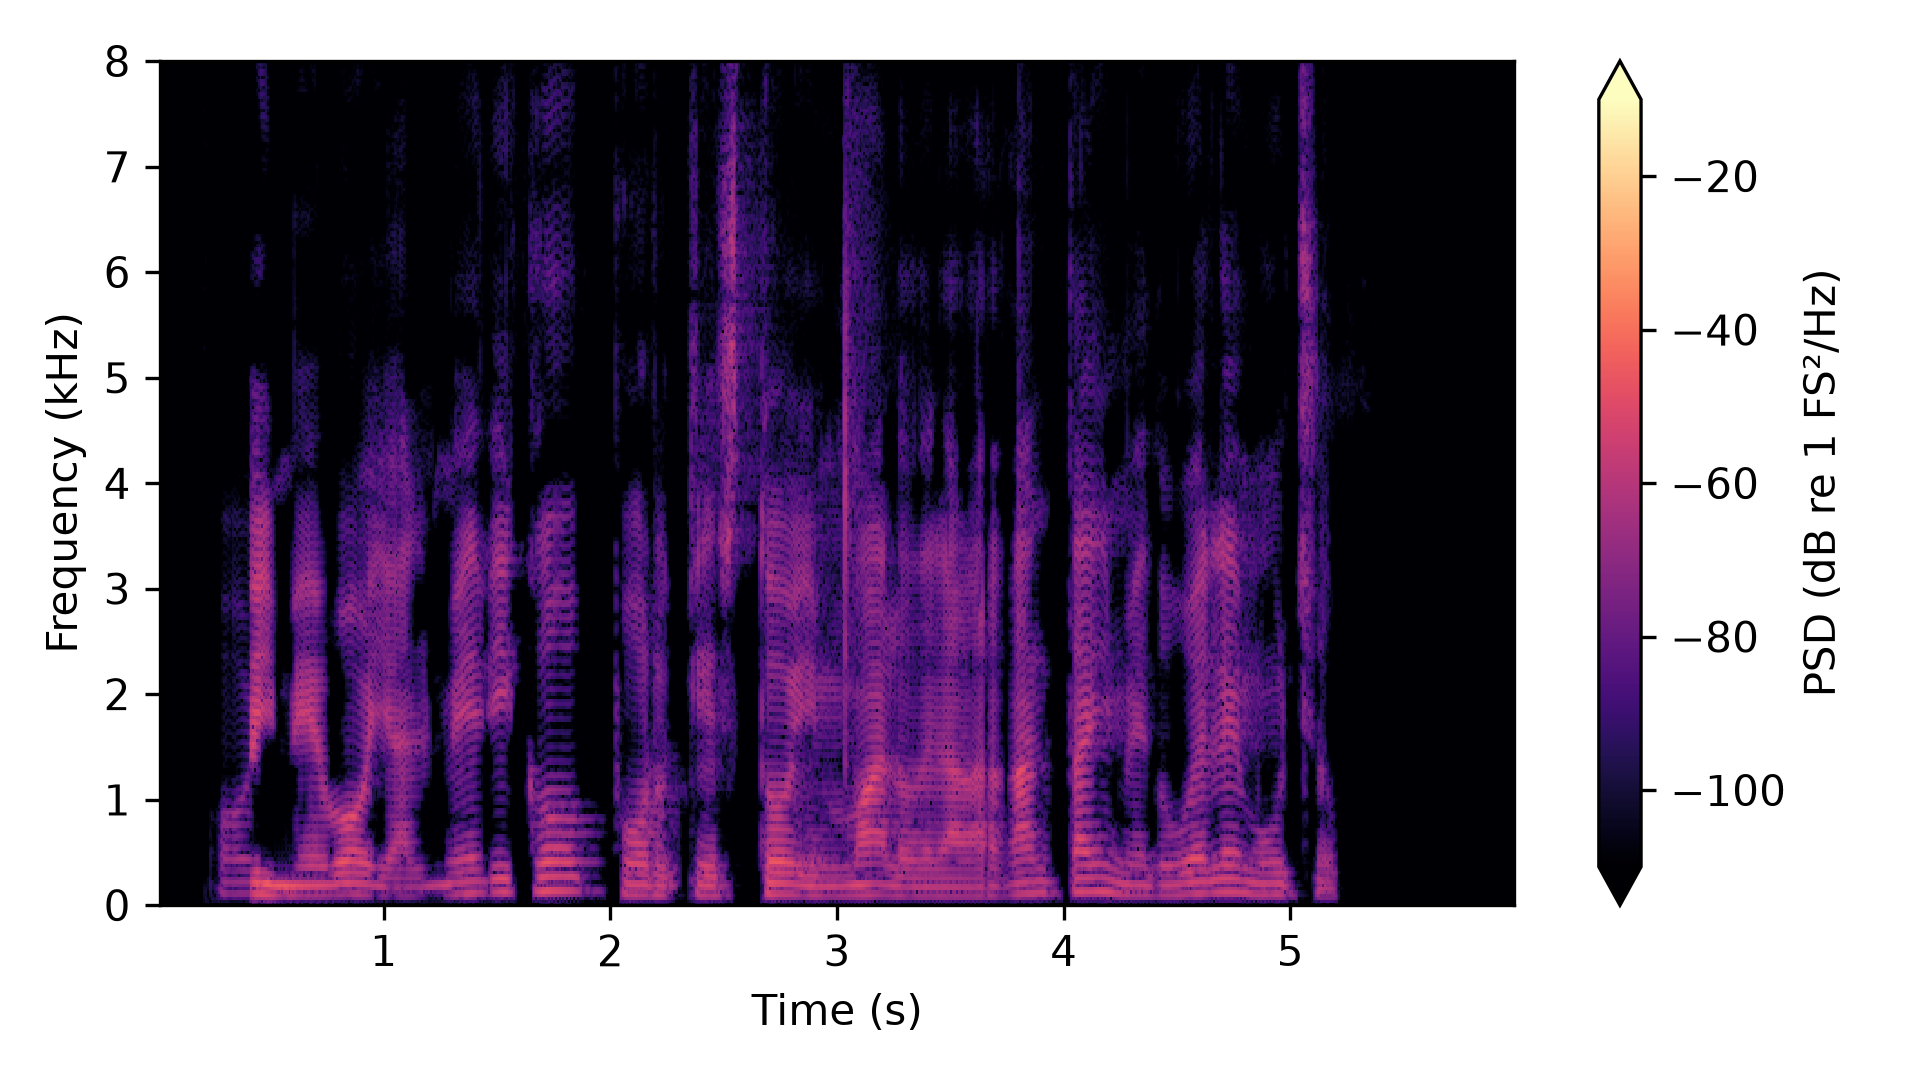

In [46]:
fig_micro, ax_micro = plt.subplots(figsize=(6.4, 3.6), dpi=300)
imagen_micro = ax_micro.pcolormesh(instantes_micro, frecuencias_micro[visibles_micro] / 1000, db_micro[visibles_micro],
                       shading="nearest", cmap="magma", vmin=-110, vmax=-10)
ax_micro.set(xlabel="Time (s)", ylabel="Frequency (kHz)",
       ylim=(0, min(FRECUENCIA_MAX_MICRO, fs_micro / 2) / 1000))
fig_micro.colorbar(imagen_micro, ax=ax_micro, label="PSD (dB re 1 FS²/Hz)", extend="both")
fig_micro.tight_layout()
plt.show()

### 2.5. Transcribir tu grabación

Reutilizamos el modelo ya cargado. Primero remuestreamos tu señal a 16 kHz;
después calculamos los logits y aplicamos la misma decodificación CTC.

In [47]:
entrada_micro = torch.from_numpy(audio_micro).unsqueeze(0)
if fs_micro != bundle.sample_rate:
    entrada_micro = torchaudio.functional.resample(entrada_micro, fs_micro, bundle.sample_rate)

print(f"Entrada: {tuple(entrada_micro.shape)}")
print(f"Audio original: {len(audio_micro) / fs_micro:.4f} s")
print(f"Audio del modelo: {entrada_micro.shape[1] / bundle.sample_rate:.4f} s")

Entrada: (1, 96000)
Audio original: 6.0000 s
Audio del modelo: 6.0000 s


In [48]:
with torch.inference_mode():
    logits_micro, _ = modelo(entrada_micro)

camino_micro = logits_micro[0].argmax(dim=-1)
sin_repeticiones_micro = torch.unique_consecutive(camino_micro)
texto_micro = "".join(etiquetas[i] for i in sin_repeticiones_micro.tolist() if i != 0)
texto_micro = " ".join(texto_micro.replace("|", " ").split())

print(f"Logits (batch, frames, tokens): {tuple(logits_micro.shape)}")
print("Camino CTC:", "".join(etiquetas[i] for i in camino_micro.tolist()))
print()
print("Transcripción:", texto_micro if texto_micro else "[Sin texto reconocido]")

Logits (batch, frames, tokens): (1, 299, 35)
Camino CTC: -----------------------yy-||---m-e--|---v--o---yy--|||aa-l-|||---m--é----d--i-----c-o-|||||-------------p-oo-r------quuue|||ee--s----t--o----|--y-n-||-----m-a----l-o-||dee|-la||a-l-a-rr---g--a--n-----t-a-||||yy-|--m-e-||-d--u----ee--ll-e--||----m-u-----ch-o---|--------------------------------------

Transcripción: y me voy al médico porque esto yn malo de la alarganta y me duele mucho


Reproduce tu grabación y contrasta la frase con la transcripción.

**Referencias y entorno.** [Wav2Vec2 y CTC en TorchAudio](https://docs.pytorch.org/audio/2.2.0/tutorials/speech_recognition_pipeline_tutorial.html),
[ejemplo de audio de SpeechBrain](https://huggingface.co/speechbrain/asr-wav2vec2-commonvoice-14-es).
Dependencias comprobadas en UNIE_VozClon: Python 3.8.20, NumPy 1.24.4,
SciPy 1.10.1, Matplotlib 3.7.5, sounddevice 0.5.6, PyTorch/TorchAudio 2.2.2.
No se necesitan scripts locales, Transformers, SpeechBrain ni un backend de lectura de TorchAudio.
La primera celda configura MKL en modo secuencial para evitar el conflicto de
runtimes OpenMP de este entorno; debe ejecutarse antes de importar NumPy o PyTorch.

## 3. Inferencia sobre mis grabaciones

Esta comparación no descarga ni modifica los archivos de `data/`. Ejecuta la celda
para transcribir `A1_clara.wav` y `A1_ruido.wav` con el mismo Wav2Vec2 y el mismo
preprocesamiento a 16 kHz.


In [49]:
from IPython.display import Markdown

rutas_propias = {
    "A1_clara.wav": Path("data/A1_clara.wav"),
    "A1_ruido.wav": Path("data/A1_ruido.wav"),
}
for ruta in rutas_propias.values():
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró la grabación requerida: {ruta}")

transcripciones_propias = {}
for nombre, ruta_propia in rutas_propias.items():
    with wave.open(str(ruta_propia), "rb") as wav:
        if wav.getnchannels() != 1 or wav.getsampwidth() != 2:
            raise ValueError(f"{ruta_propia} debe ser un WAV mono PCM de 16 bits.")
        frecuencia_propia = wav.getframerate()
        audio_propio = np.frombuffer(
            wav.readframes(wav.getnframes()), dtype="<i2"
        ).astype(np.float32) / 32768

    if audio_propio.size == 0 or not np.isfinite(audio_propio).all():
        raise ValueError(f"La grabación {ruta_propia} está vacía o contiene valores no válidos.")
    entrada_propia = torch.from_numpy(audio_propio).unsqueeze(0)
    if frecuencia_propia != bundle.sample_rate:
        entrada_propia = torchaudio.functional.resample(
            entrada_propia, frecuencia_propia, bundle.sample_rate
        )

    with torch.inference_mode():
        logits_propios, _ = modelo(entrada_propia)
    camino_propio = logits_propios[0].argmax(dim=-1)
    tokens_propios = torch.unique_consecutive(camino_propio)
    texto_propio = "".join(
        etiquetas[i] for i in tokens_propios.tolist() if i != 0
    )
    transcripciones_propias[nombre] = " ".join(texto_propio.replace("|", " ").split())
    print(f"{nombre}: {transcripciones_propias[nombre] or '[Sin texto reconocido]'}")


A1_clara.wav: pola soisanti y me gusta mucho jugar al gte a seisa
A1_ruido.wav: olasoy santi y me gusta mucho jugar al gta seis ti


## Análisis de resultados

| Grabación | Condición | Transcripción de Wav2Vec2 | Errores de caracteres (CER) |
|---|---|---|---|
| `A1_clara.wav` | Voz clara, cerca del micrófono | pola soisanti y me gusta mucho jugar al gte a seisa | hola soy santi y me gusta mucho jugar al gta seis |
| `A1_ruido.wav` | Con ruido de fondo o mayor distancia | olasoy santi y me gusta mucho jugar al gta seis ti | hola soy santi y me gusta mucho jugar al gta seis |

Compara primero que ambas grabaciones contengan la misma frase y anota la
transcripción obtenida. El CER se calcula como `(sustituciones + eliminaciones +
inserciones) / caracteres de referencia`; utiliza idéntica normalización (por
ejemplo, minúsculas y puntuación eliminada) en los dos casos. Los valores no se
pueden completar sin conocer la transcripción de referencia.

Una relación señal-ruido (SNR) más baja hace que el habla quede menos diferenciada
del ruido. Si la persona se aleja del micrófono, suele disminuir el nivel de la voz
directa y aumenta la influencia relativa del ruido ambiental y la reverberación.
Estas condiciones pueden ocultar consonantes o distorsionar rasgos acústicos, lo que
incrementa sustituciones, eliminaciones o inserciones del decodificador; no garantizan
un CER peor en cada toma. La comparación debe considerar también la pronunciación,
el micrófono y el nivel de grabación.


## Interpretación de resultados (ASR con Wav2Vec2)
* **Audio limpio (`data/A1_clara.wav` y `data/example_es.wav`)**: el modelo transcribe con mayor fidelidad la secuencia fonética y léxica cuando la relación señal/ruido es favorable.
* **Audio con ruido (`data/A1_ruido.wav`)**: el ruido de fondo compite con la señal acústica y suele provocar sustituciones de palabras, omisiones o transcripciones parciales, especialmente en sílabas débiles o finales de palabra.
* **Conclusión**: un ASR preentrenado sin preprocesado o filtrado adicional es sensible al ruido ambiental; en condiciones reales conviene cuidar la captura o aplicar técnicas de reducción de ruido/adaptación.